#### Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from collections import Counter
import re

#### Loading the Dataset

In [2]:
data_path = Path("../data/raw/20000-Utterances-Training-dataset-for-chatbots-virtual-assistant-Bitext-sample.csv")
df = pd.read_csv(data_path)
print(f"Dataset Shape: {df.shape}")
display(df.head())

Dataset Shape: (21534, 4)


,flags,utterance,category,intent
0,BILC,"I don't have an online account, what do I have...",ACCOUNT,create_account
1,BILQZ,can you tell me if i can regisger two accounts...,ACCOUNT,create_account
2,BPLC,"I have no online account, open one, please",ACCOUNT,create_account
3,BIPLD,"could you ask an agent how to open an account,...",ACCOUNT,create_account
4,BLQC,"i want an online account, create one",ACCOUNT,create_account


#### 2. Univariate Analysis

#### Visualizing Customer Service Category Distribution

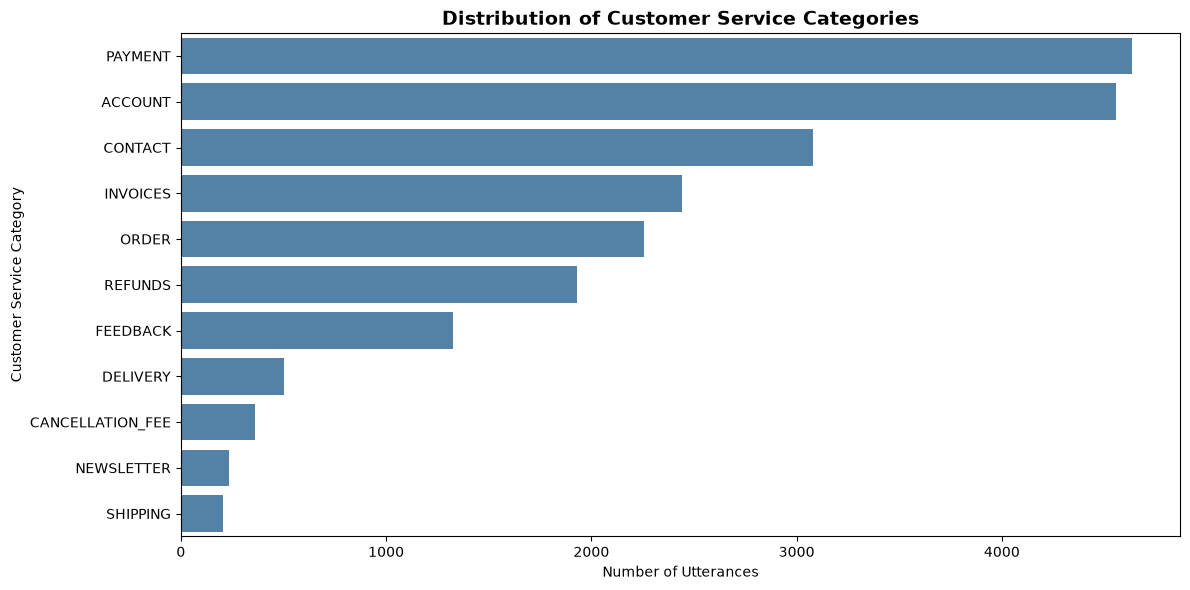

In [3]:
category_counts = df["category"].value_counts()

plt.figure(figsize=(12, 6))
sns.barplot(
    x=category_counts.values,
    y=category_counts.index,
    color="steelblue"
)
plt.title("Distribution of Customer Service Categories", fontsize=14, fontweight="bold")
plt.xlabel("Number of Utterances")
plt.ylabel("Customer Service Category")
plt.tight_layout()
plt.show()

#### Observations
- **PAYMENT (4,636)** and **ACCOUNT (4,557)** are the most represented categories, collectively accounting for 42.69% of customer utterances.
- **CONTACT (3,081)** and **INVOICES (2,443)** also contribute substantially, while SHIPPING (206) has the fewest records.
- **Key Finding:** Customer queries are unevenly distributed across service categories, indicating substantial category-level imbalance.

#### Visualizing Customer Intent Distribution

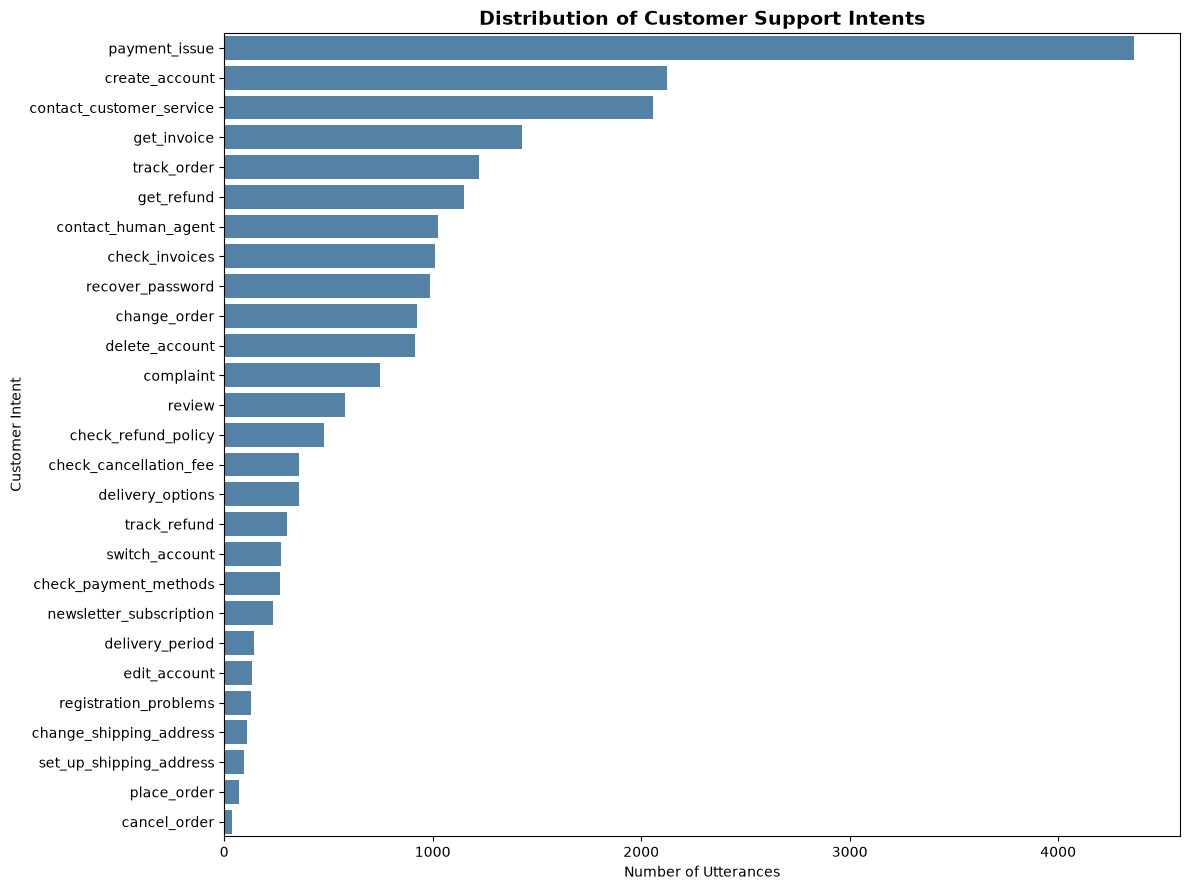

,Intent,Count
0,payment_issue,4366
1,create_account,2122
2,contact_customer_service,2055
3,get_invoice,1430
4,track_order,1224
5,get_refund,1150
6,contact_human_agent,1026
7,check_invoices,1013
8,recover_password,986
9,change_order,926


In [4]:
intent_counts = df["intent"].value_counts()

plt.figure(figsize=(12, 9))
sns.barplot(
    x=intent_counts.values,
    y=intent_counts.index,
    color="steelblue"
)
plt.title("Distribution of Customer Support Intents", fontsize=14, fontweight="bold")
plt.xlabel("Number of Utterances")
plt.ylabel("Customer Intent")
plt.tight_layout()
plt.show()

display(intent_counts.reset_index(name="Count").rename(columns={"intent": "Intent"}))

#### Observations
- **`payment_issue` (4,366)** is the dominant intent, accounting for 20.27% of all customer utterances.
- **`cancel_order` (36)** and **`place_order` (70)** are the least represented intents, highlighting substantial class imbalance.
- **Modeling Implication:** Prioritize stratified data splitting and Macro F1-score to ensure minority intent classes receive appropriate consideration during evaluation.

#### Visualizing Customer Utterance Word Count Distribution

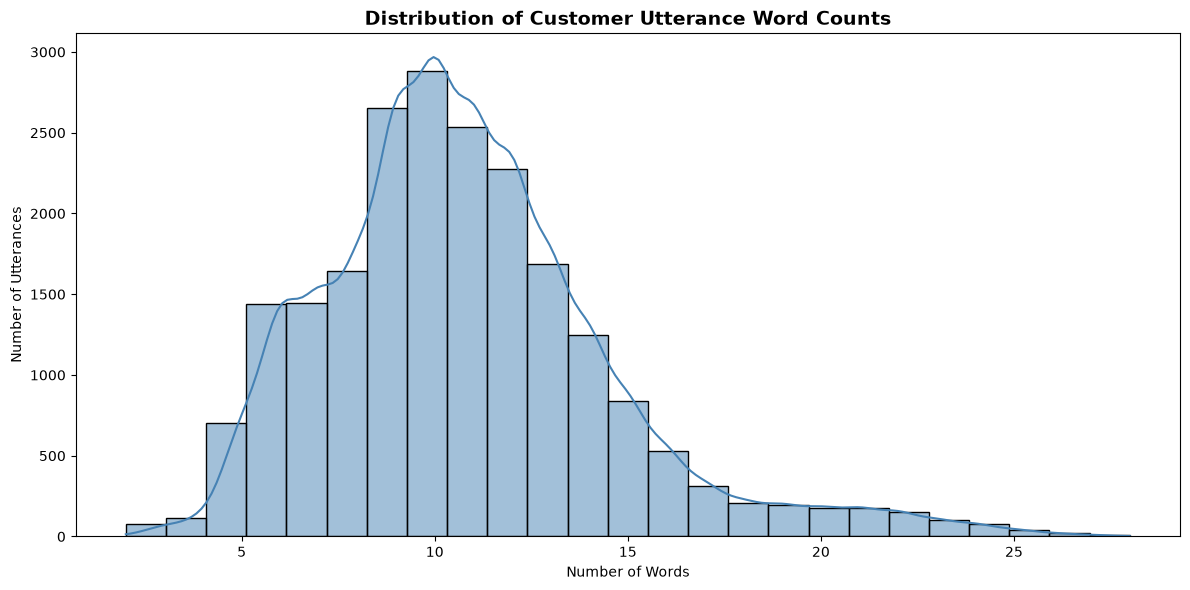

count    21534.00
mean        10.86
std          3.72
min          2.00
25%          8.00
50%         10.00
75%         13.00
max         28.00
Name: Word_Count, dtype: float64

In [5]:
df["Word_Count"] = df["utterance"].str.split().str.len()

plt.figure(figsize=(12, 6))
sns.histplot(
    data=df,
    x="Word_Count",
    bins=25,
    kde=True,
    color="steelblue"
)
plt.title("Distribution of Customer Utterance Word Counts", fontsize=14, fontweight="bold")
plt.xlabel("Number of Words")
plt.ylabel("Number of Utterances")
plt.tight_layout()
plt.show()

display(df["Word_Count"].describe().round(2))

#### Observations
- Customer utterances contain an average of **10.86 words**, with a median of 10 words.
- **50% of utterances contain 8–13 words**, while overall query lengths range from 2 to 28 words.
- **Key Finding:** The dataset primarily consists of short customer queries, making word-level and character-level text representations worth exploring during feature engineering.

#### Visualizing Customer Utterance Character Count Distribution

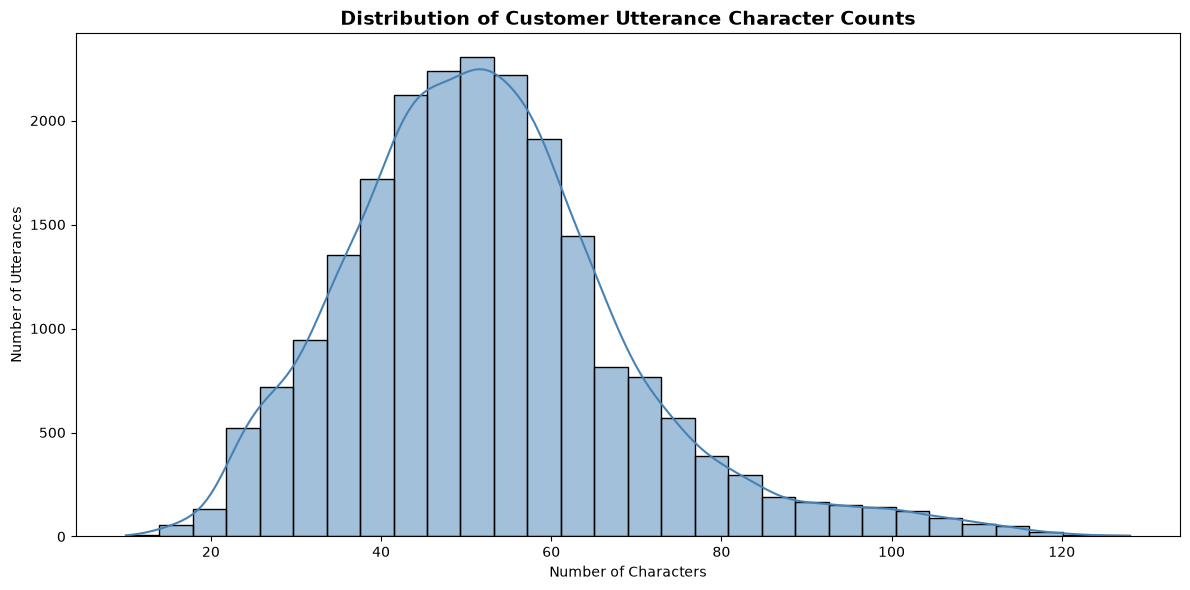

count    21534.00
mean        52.54
std         16.79
min         10.00
25%         41.00
50%         51.00
75%         61.00
max        128.00
Name: Character_Count, dtype: float64

In [6]:
df["Character_Count"] = df["utterance"].str.len()

plt.figure(figsize=(12, 6))
sns.histplot(
    data=df,
    x="Character_Count",
    bins=30,
    kde=True,
    color="steelblue"
)
plt.title("Distribution of Customer Utterance Character Counts", fontsize=14, fontweight="bold")
plt.xlabel("Number of Characters")
plt.ylabel("Number of Utterances")
plt.tight_layout()
plt.show()

display(df["Character_Count"].describe().round(2))

#### Observations
- Customer utterances average **52.54 characters**, with a median length of 51 characters.
- **50% of utterances contain 41–61 characters**, while lengths range from 10 to 128 characters.
- **Key Finding:** Character lengths show moderate variability, supporting the exploration of character-level TF-IDF features alongside word-level representations.

#### 3. Bivariate Analysis

#### Visualizing Word Count Distribution Across Customer Service Categories

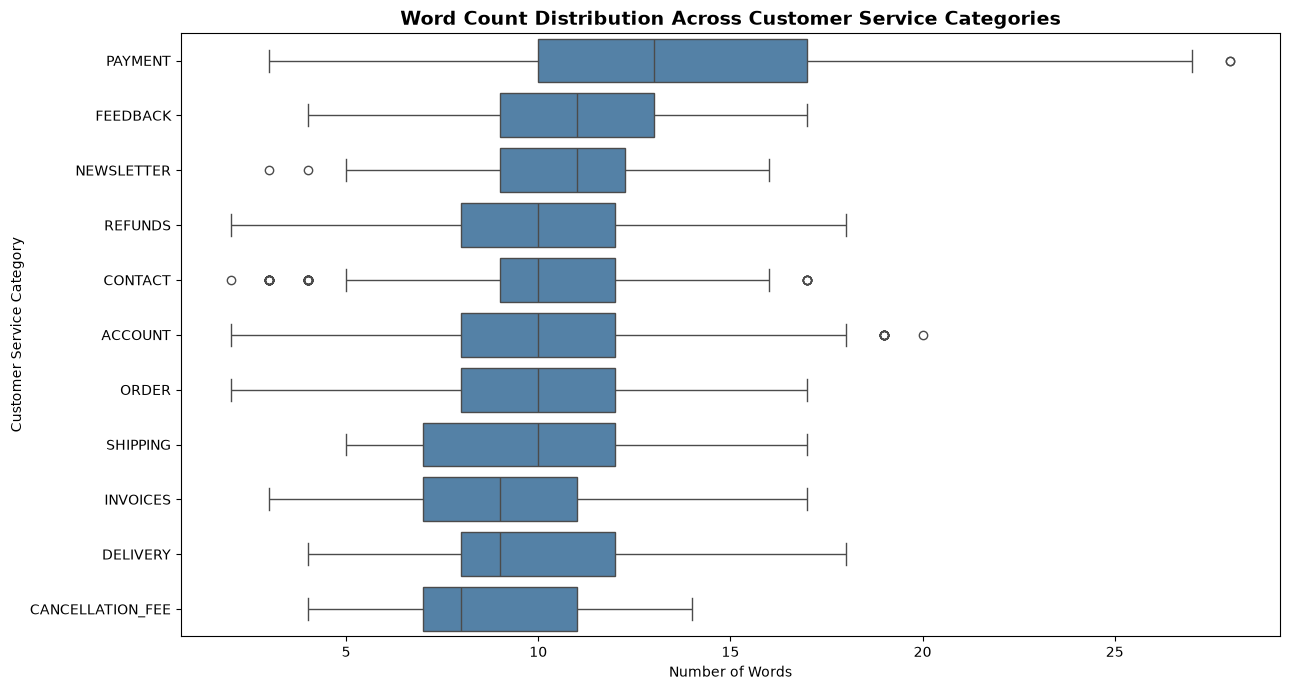

,mean,median,min,max
category,,,,
PAYMENT,13.80,13.0,3,28
FEEDBACK,10.90,11.0,4,17
NEWSLETTER,10.58,11.0,3,16
REFUNDS,9.94,10.0,2,18
CONTACT,10.16,10.0,2,17
ACCOUNT,10.40,10.0,2,20
ORDER,9.82,10.0,2,17
SHIPPING,10.08,10.0,5,17
INVOICES,9.32,9.0,3,17


In [7]:
category_order = (
    df.groupby("category")["Word_Count"]
    .median()
    .sort_values(ascending=False)
    .index
)

plt.figure(figsize=(13, 7))
sns.boxplot(
    data=df,
    x="Word_Count",
    y="category",
    order=category_order,
    color="steelblue"
)
plt.title("Word Count Distribution Across Customer Service Categories", fontsize=14, fontweight="bold")
plt.xlabel("Number of Words")
plt.ylabel("Customer Service Category")
plt.tight_layout()
plt.show()

category_word_summary = (
    df.groupby("category")["Word_Count"]
    .agg(["mean", "median", "min", "max"])
    .round(2)
    .sort_values("median", ascending=False)
)
display(category_word_summary)

#### Observations
- **PAYMENT has the longest utterances**, averaging 13.80 words, with a median of 13 words and a maximum of 28 words.
- **CANCELLATION_FEE has the shortest utterances**, averaging 8.59 words, with a median of 8 words.
- **Key Finding:** Utterance lengths vary across service categories, with payment-related queries generally containing more words than other customer requests.

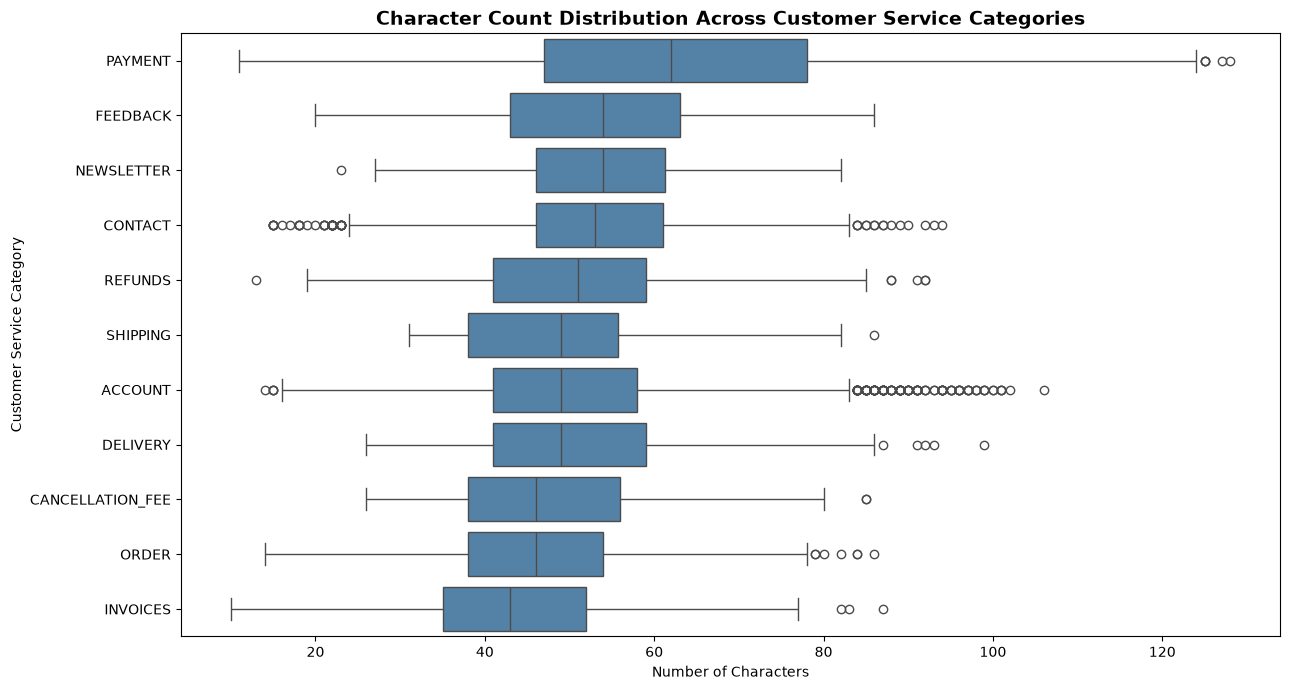

,mean,median,min,max
category,,,,
PAYMENT,63.96,62.0,11,128
FEEDBACK,53.11,54.0,20,86
NEWSLETTER,54.16,54.0,23,82
CONTACT,53.06,53.0,15,94
REFUNDS,50.56,51.0,13,92
SHIPPING,48.58,49.0,31,86
ACCOUNT,50.43,49.0,14,106
DELIVERY,50.99,49.0,26,99
CANCELLATION_FEE,47.66,46.0,26,85


In [8]:
category_char_order = (
    df.groupby("category")["Character_Count"]
    .median()
    .sort_values(ascending=False)
    .index
)

plt.figure(figsize=(13, 7))
sns.boxplot(
    data=df,
    x="Character_Count",
    y="category",
    order=category_char_order,
    color="steelblue"
)
plt.title("Character Count Distribution Across Customer Service Categories", fontsize=14, fontweight="bold")
plt.xlabel("Number of Characters")
plt.ylabel("Customer Service Category")
plt.tight_layout()
plt.show()

category_char_summary = (
    df.groupby("category")["Character_Count"]
    .agg(["mean", "median", "min", "max"])
    .round(2)
    .sort_values("median", ascending=False)
)
display(category_char_summary)

#### Observations
- **PAYMENT has the longest utterances**, averaging 63.96 characters, with a median of 62 and a maximum of 128 characters.
- **INVOICES has the shortest average character length (43.15)**, followed by ORDER (45.52) and CANCELLATION_FEE (47.66).
- **Key Finding:** PAYMENT consistently contains longer queries across both word and character counts, while the shortest categories differ depending on the length metric.

#### Visualizing Word Count Distribution Across Customer Intents

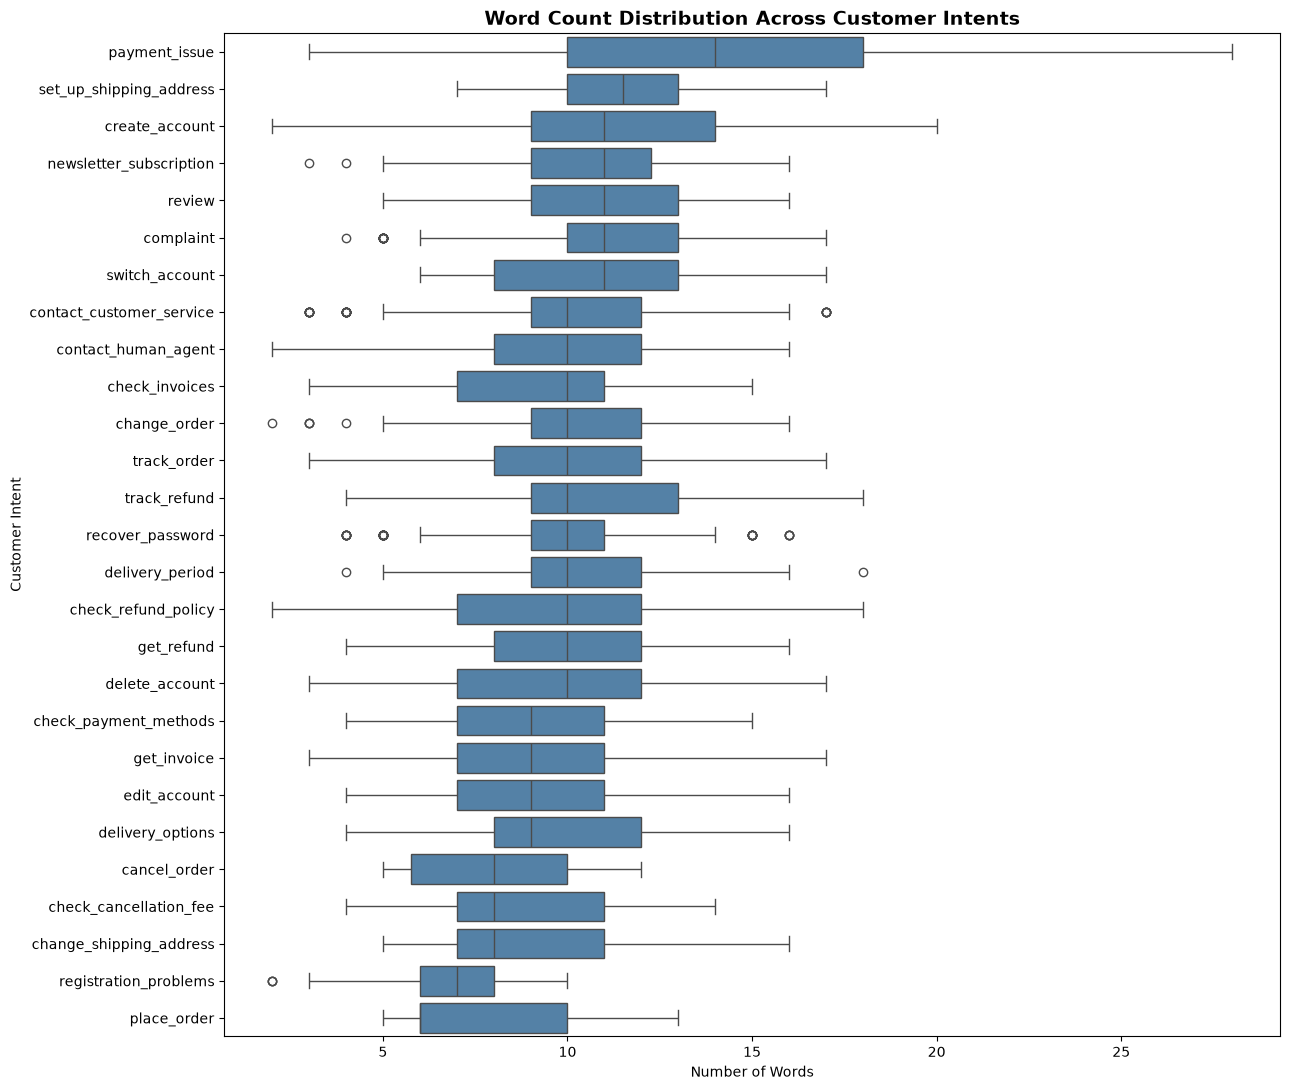

,mean,median,min,max
intent,,,,
payment_issue,14.10,14.0,3,28
set_up_shipping_address,11.49,11.5,7,17
create_account,11.21,11.0,2,20
newsletter_subscription,10.58,11.0,3,16
review,10.51,11.0,5,16
complaint,11.21,11.0,4,17
switch_account,10.39,11.0,6,17
contact_customer_service,10.29,10.0,3,17
contact_human_agent,9.91,10.0,2,16


In [9]:
intent_word_order = (
    df.groupby("intent")["Word_Count"]
    .median()
    .sort_values(ascending=False)
    .index
)

plt.figure(figsize=(13, 11))
sns.boxplot(
    data=df,
    x="Word_Count",
    y="intent",
    order=intent_word_order,
    color="steelblue"
)
plt.title("Word Count Distribution Across Customer Intents", fontsize=14, fontweight="bold")
plt.xlabel("Number of Words")
plt.ylabel("Customer Intent")
plt.tight_layout()
plt.show()

intent_word_summary = (
    df.groupby("intent")["Word_Count"]
    .agg(["mean", "median", "min", "max"])
    .round(2)
    .sort_values("median", ascending=False)
)
display(intent_word_summary)

#### Observations
- **`payment_issue` has the longest utterances**, averaging 14.10 words, followed by `set_up_shipping_address` (11.49) and `create_account` (11.21).
- **`registration_problems` (6.77)** and **`place_order` (7.74)** have the shortest average utterances, indicating more concise customer requests.
- **Key Finding:** Word-count patterns differ across intents, suggesting that query length may provide supplementary information for classification alongside textual features.

#### Visualizing Character Count Distribution Across Customer Intents

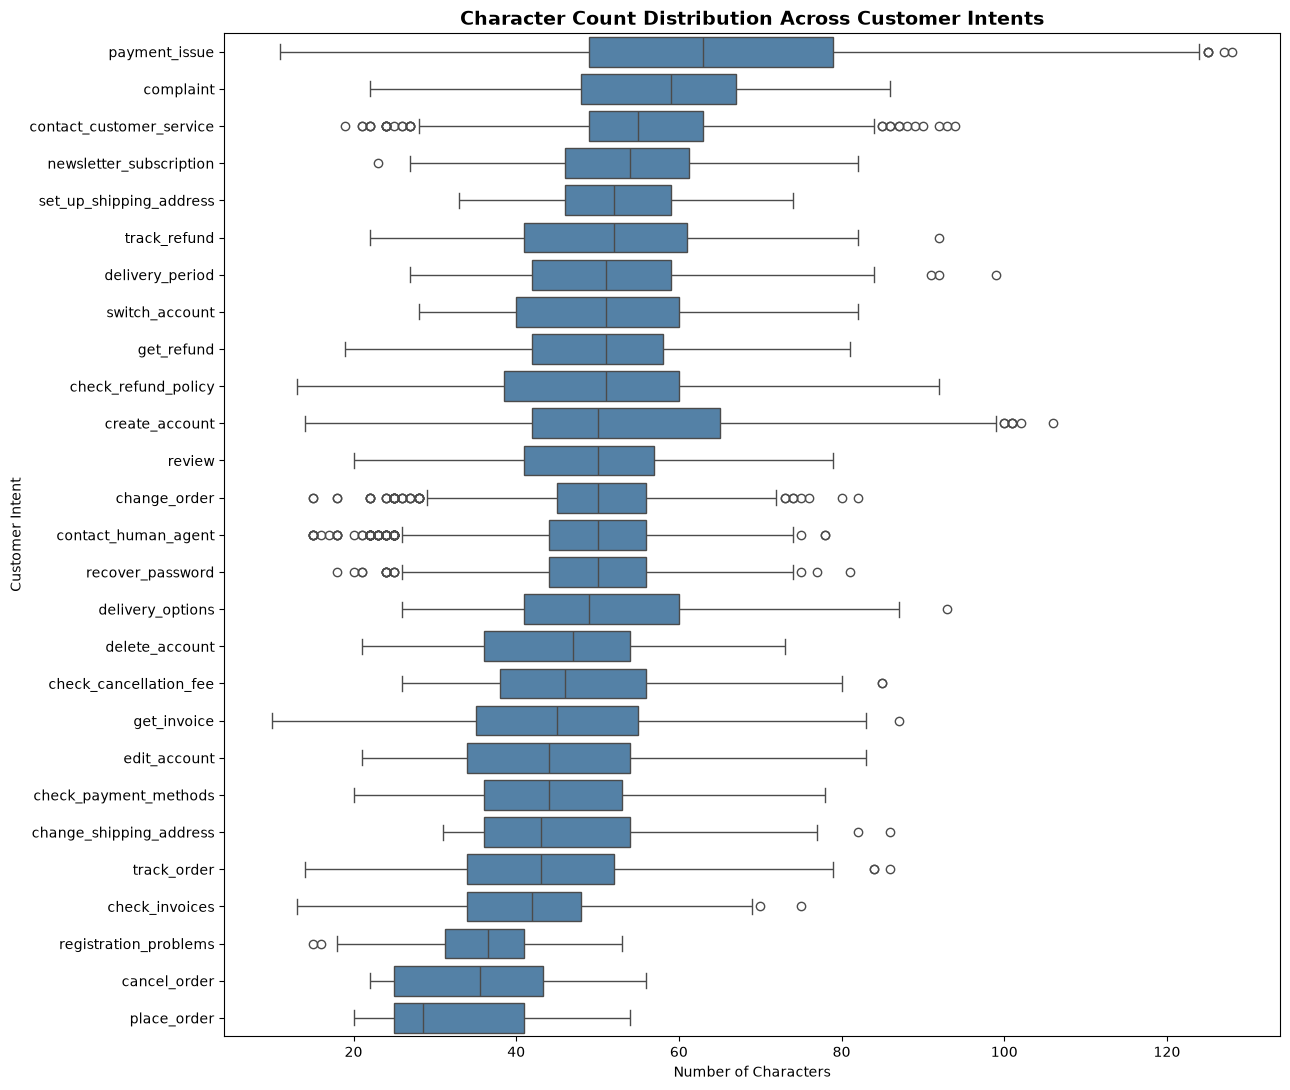

,mean,median,min,max
intent,,,,
payment_issue,65.14,63.0,11,128
complaint,57.00,59.0,22,86
contact_customer_service,55.20,55.0,19,94
newsletter_subscription,54.16,54.0,23,82
set_up_shipping_address,51.72,52.0,33,74
track_refund,51.24,52.0,22,92
delivery_period,52.19,51.0,27,99
switch_account,50.84,51.0,28,82
get_refund,50.16,51.0,19,81


In [10]:
intent_char_order = (
    df.groupby("intent")["Character_Count"]
    .median()
    .sort_values(ascending=False)
    .index
)

plt.figure(figsize=(13, 11))
sns.boxplot(
    data=df,
    x="Character_Count",
    y="intent",
    order=intent_char_order,
    color="steelblue"
)
plt.title("Character Count Distribution Across Customer Intents", fontsize=14, fontweight="bold")
plt.xlabel("Number of Characters")
plt.ylabel("Customer Intent")
plt.tight_layout()
plt.show()

intent_char_summary = (
    df.groupby("intent")["Character_Count"]
    .agg(["mean", "median", "min", "max"])
    .round(2)
    .sort_values("median", ascending=False)
)
display(intent_char_summary)

#### Observations
- **`payment_issue` has the longest utterances**, averaging 65.14 characters, followed by `complaint` (57.00) and `contact_customer_service` (55.20).
- **`place_order` (32.81)** and **`cancel_order` (35.25)** have the shortest average character lengths, indicating more concise requests.
- **Key Finding:** Character-length differences reinforce the word-count findings, suggesting that text length may provide supplementary predictive information alongside vocabulary patterns.

## 4. Linguistic and Vocabulary Analysis

#### Examining Most Frequent Words in Customer Utterances

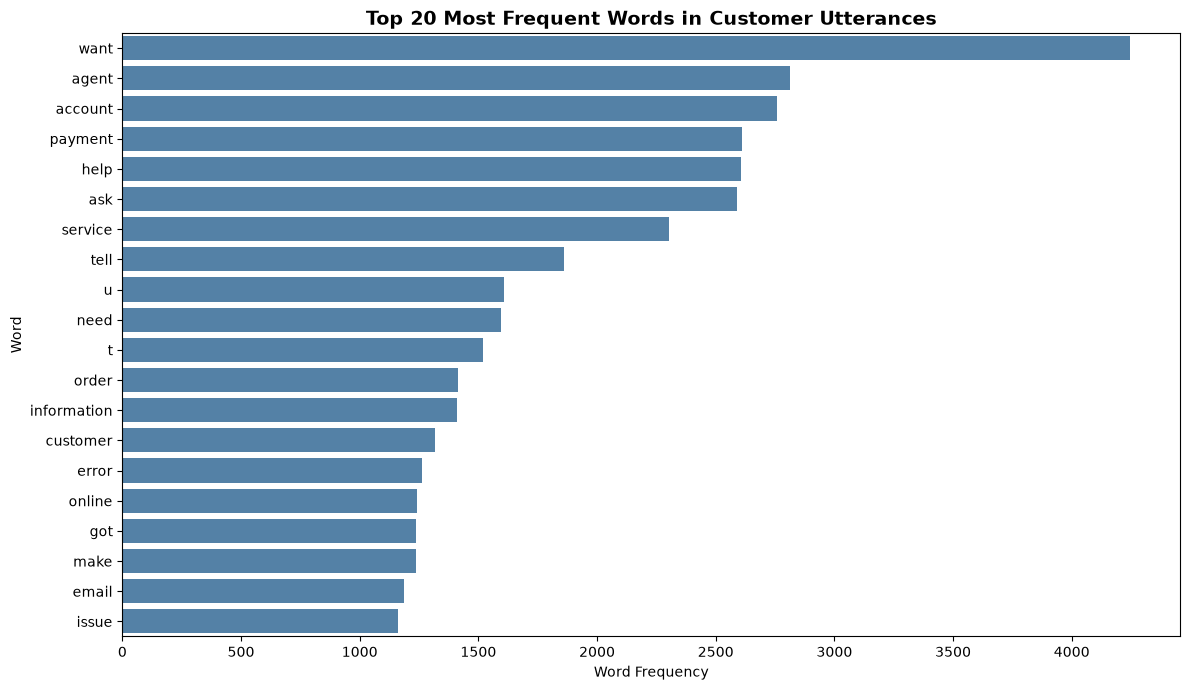

,Word,Frequency
0,want,4244
1,agent,2815
2,account,2760
3,payment,2610
4,help,2608
5,ask,2589
6,service,2304
7,tell,1860
8,u,1608
9,need,1597


In [11]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

all_tokens = [
    token
    for text in df["utterance"].str.lower()
    for token in re.findall(r"\b[a-z]+\b", text)
    if token not in ENGLISH_STOP_WORDS
]

word_frequencies = (
    pd.DataFrame(
        Counter(all_tokens).most_common(20),
        columns=["Word", "Frequency"]
    )
)

plt.figure(figsize=(12, 7))
sns.barplot(
    data=word_frequencies,
    x="Frequency",
    y="Word",
    color="steelblue"
)
plt.title("Top 20 Most Frequent Words in Customer Utterances", fontsize=14, fontweight="bold")
plt.xlabel("Word Frequency")
plt.ylabel("Word")
plt.tight_layout()
plt.show()

display(word_frequencies)

#### Observations
- **`want` (4,244)** is the most frequent word, followed by `agent` (2,815), `account` (2,760), and `payment` (2,610).
- Frequent terms such as **`order`, `error`, `service`, and `customer`** reflect the dataset's major customer support topics.
- **Key Finding:** Tokens such as `u` and `t` suggest that contractions and informal language affect token frequencies, highlighting the importance of evaluating tokenization strategies.

#### Examining Vocabulary Diversity

In [12]:
token_counts = Counter(all_tokens)

vocabulary_summary = pd.DataFrame({
    "Metric": [
        "Total Tokens",
        "Unique Tokens",
        "Tokens Appearing Once",
        "Tokens Appearing Five Times or Fewer",
        "Average Token Frequency"
    ],
    "Value": [
        sum(token_counts.values()),
        len(token_counts),
        sum(count == 1 for count in token_counts.values()),
        sum(count <= 5 for count in token_counts.values()),
        round(np.mean(list(token_counts.values())), 2)
    ]
})
display(vocabulary_summary)

,Metric,Value
0,Total Tokens,95422.00
1,Unique Tokens,1898.00
2,Tokens Appearing Once,1242.00
3,Tokens Appearing Five Times or Fewer,1623.00
4,Average Token Frequency,50.28


#### Observations
- The dataset contains **95,422 tokens across 1,898 unique words**, after applying the current tokenization and stopword-removal approach.
- **1,242 unique words (65.44%) appear only once**, while 1,623 (85.51%) occur five times or fewer.
- **Key Finding:** Rare words make up a substantial portion of the vocabulary, suggesting that TF-IDF vocabulary filtering and character-level features may help manage sparsity and spelling variations.

#### Visualizing Vocabulary Frequency Distribution

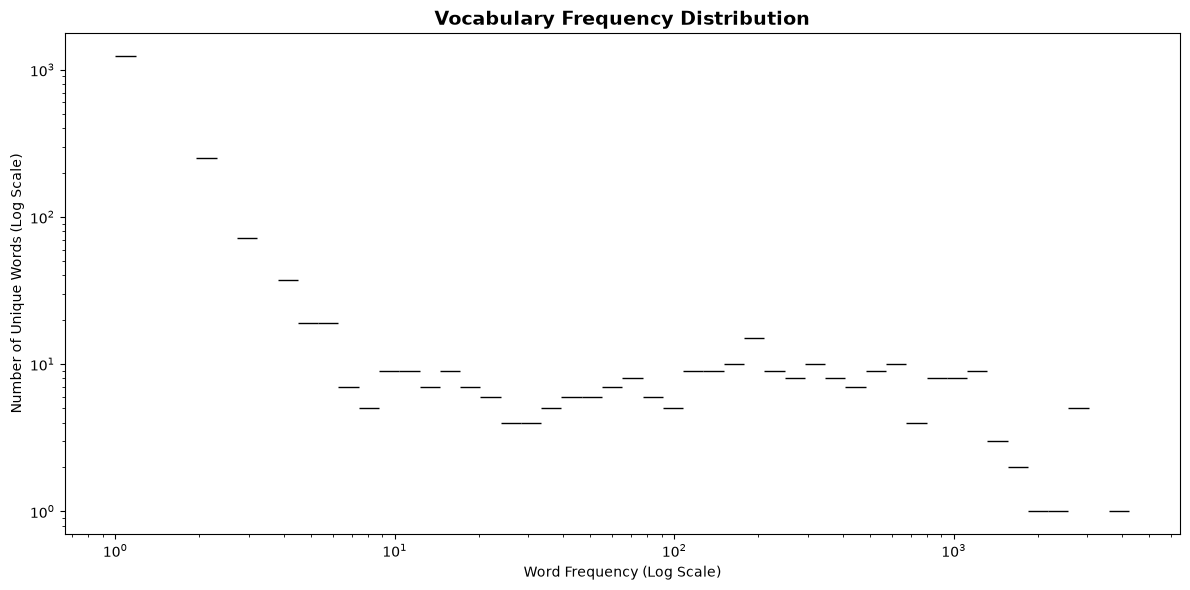

,Frequency Range,Unique Words
0,Appearing Once,1242
1,Appearing 2–5 Times,381
2,Appearing 6–20 Times,72
3,Appearing 21–100 Times,56
4,Appearing More Than 100 Times,147


In [13]:
word_frequency_values = list(token_counts.values())

plt.figure(figsize=(12, 6))
sns.histplot(
    word_frequency_values,
    bins=50,
    log_scale=(True, True),
    color="steelblue"
)
plt.title("Vocabulary Frequency Distribution", fontsize=14, fontweight="bold")
plt.xlabel("Word Frequency (Log Scale)")
plt.ylabel("Number of Unique Words (Log Scale)")
plt.tight_layout()
plt.show()

frequency_summary = pd.DataFrame({
    "Frequency Range": [
        "Appearing Once",
        "Appearing 2–5 Times",
        "Appearing 6–20 Times",
        "Appearing 21–100 Times",
        "Appearing More Than 100 Times"
    ],
    "Unique Words": [
        sum(count == 1 for count in word_frequency_values),
        sum(2 <= count <= 5 for count in word_frequency_values),
        sum(6 <= count <= 20 for count in word_frequency_values),
        sum(21 <= count <= 100 for count in word_frequency_values),
        sum(count > 100 for count in word_frequency_values)
    ]
})
display(frequency_summary)

#### Observations
- **1,623 unique words (85.51%) occur five times or fewer**, confirming a substantial long tail of infrequent vocabulary.
- Only **147 words (7.74%) appear more than 100 times**, indicating that a relatively small vocabulary subset occurs frequently.
- **Key Finding:** The uneven frequency distribution supports evaluating TF-IDF vocabulary filtering while retaining potentially informative rare terms.

#### Examining Frequently Occurring Words Across Customer Intents

In [14]:
intent_top_words = []

for intent, group in df.groupby("intent"):
    tokens = [
        token
        for text in group["utterance"].str.lower()
        for token in re.findall(r"\b[a-z]+\b", text)
        if token not in ENGLISH_STOP_WORDS and len(token) > 1
    ]
    top_words = Counter(tokens).most_common(5)
    intent_top_words.append({
        "Intent": intent,
        "Top 5 Words": ", ".join(
            f"{word} ({count})" for word, count in top_words
        )
    })

intent_word_summary = pd.DataFrame(intent_top_words)
display(intent_word_summary)

,Intent,Top 5 Words
0,cancel_order,"cancel (33), order (20), purchase (16), want (..."
1,change_order,"purchase (456), order (452), change (389), mod..."
2,change_shipping_address,"shipping (108), address (107), update (25), as..."
3,check_cancellation_fee,"cancellation (343), check (95), fee (94), pena..."
4,check_invoices,"check (296), view (267), invoices (255), invoi..."
5,check_payment_methods,"payment (235), methods (110), options (94), wa..."
6,check_refund_policy,"policy (341), money (218), refund (131), want ..."
7,complaint,"complaint (730), service (552), consumer (350)..."
8,contact_customer_service,"service (1367), customer (1317), client (696),..."
9,contact_human_agent,"human (509), helping (435), understand (406), ..."


#### Observations
- **Intent-specific keywords** such as `cancellation`, `newsletter`, `password`, and `reimbursement` reveal recognizable vocabulary patterns across customer requests.
- **Related intents share vocabulary**, particularly order management, account operations, and refund-related requests, potentially making them harder to distinguish.
- **Key Finding:** Intent classification requires contextual word combinations rather than relying solely on individual keywords, supporting the exploration of word-level TF-IDF n-grams.

#### Examining Vocabulary Overlap Between Customer Intents

In [15]:
intent_vocabularies = {}

for intent, group in df.groupby("intent"):
    tokens = [
        token
        for text in group["utterance"].str.lower()
        for token in re.findall(r"\b[a-z]+\b", text)
        if token not in ENGLISH_STOP_WORDS and len(token) > 1
    ]
    intent_vocabularies[intent] = set(tokens)

overlap_results = []

intents = sorted(intent_vocabularies)

for i, intent_a in enumerate(intents):
    for intent_b in intents[i + 1:]:
        vocab_a = intent_vocabularies[intent_a]
        vocab_b = intent_vocabularies[intent_b]

        intersection = len(vocab_a & vocab_b)
        union = len(vocab_a | vocab_b)

        overlap_results.append({
            "Intent A": intent_a,
            "Intent B": intent_b,
            "Shared Words": intersection,
            "Jaccard Similarity": round(intersection / union, 3) if union else 0
        })

vocabulary_overlap = (
    pd.DataFrame(overlap_results)
    .sort_values("Jaccard Similarity", ascending=False)
)

display(vocabulary_overlap.head(15))

,Intent A,Intent B,Shared Words,Jaccard Similarity
62,change_shipping_address,edit_account,18,0.353
18,cancel_order,place_order,9,0.310
22,cancel_order,set_up_shipping_address,7,0.233
71,change_shipping_address,set_up_shipping_address,10,0.227
67,change_shipping_address,place_order,10,0.222
326,place_order,set_up_shipping_address,8,0.205
140,check_payment_methods,track_refund,19,0.200
277,edit_account,place_order,10,0.192
1,cancel_order,change_shipping_address,7,0.184
126,check_payment_methods,delivery_options,17,0.173


#### Observations
- **`change_shipping_address` and `edit_account`** show the highest vocabulary overlap (0.353), sharing 18 unique words.
- **`cancel_order` and `place_order`** have the second-highest similarity (0.310), despite representing different customer actions.
- **Key Finding:** Several distinct intents share vocabulary, reinforcing the importance of contextual features such as word n-grams. Jaccard similarity alone does not establish semantic similarity or classification difficulty.

#### Visualizing Vocabulary Similarity Across Customer Intents

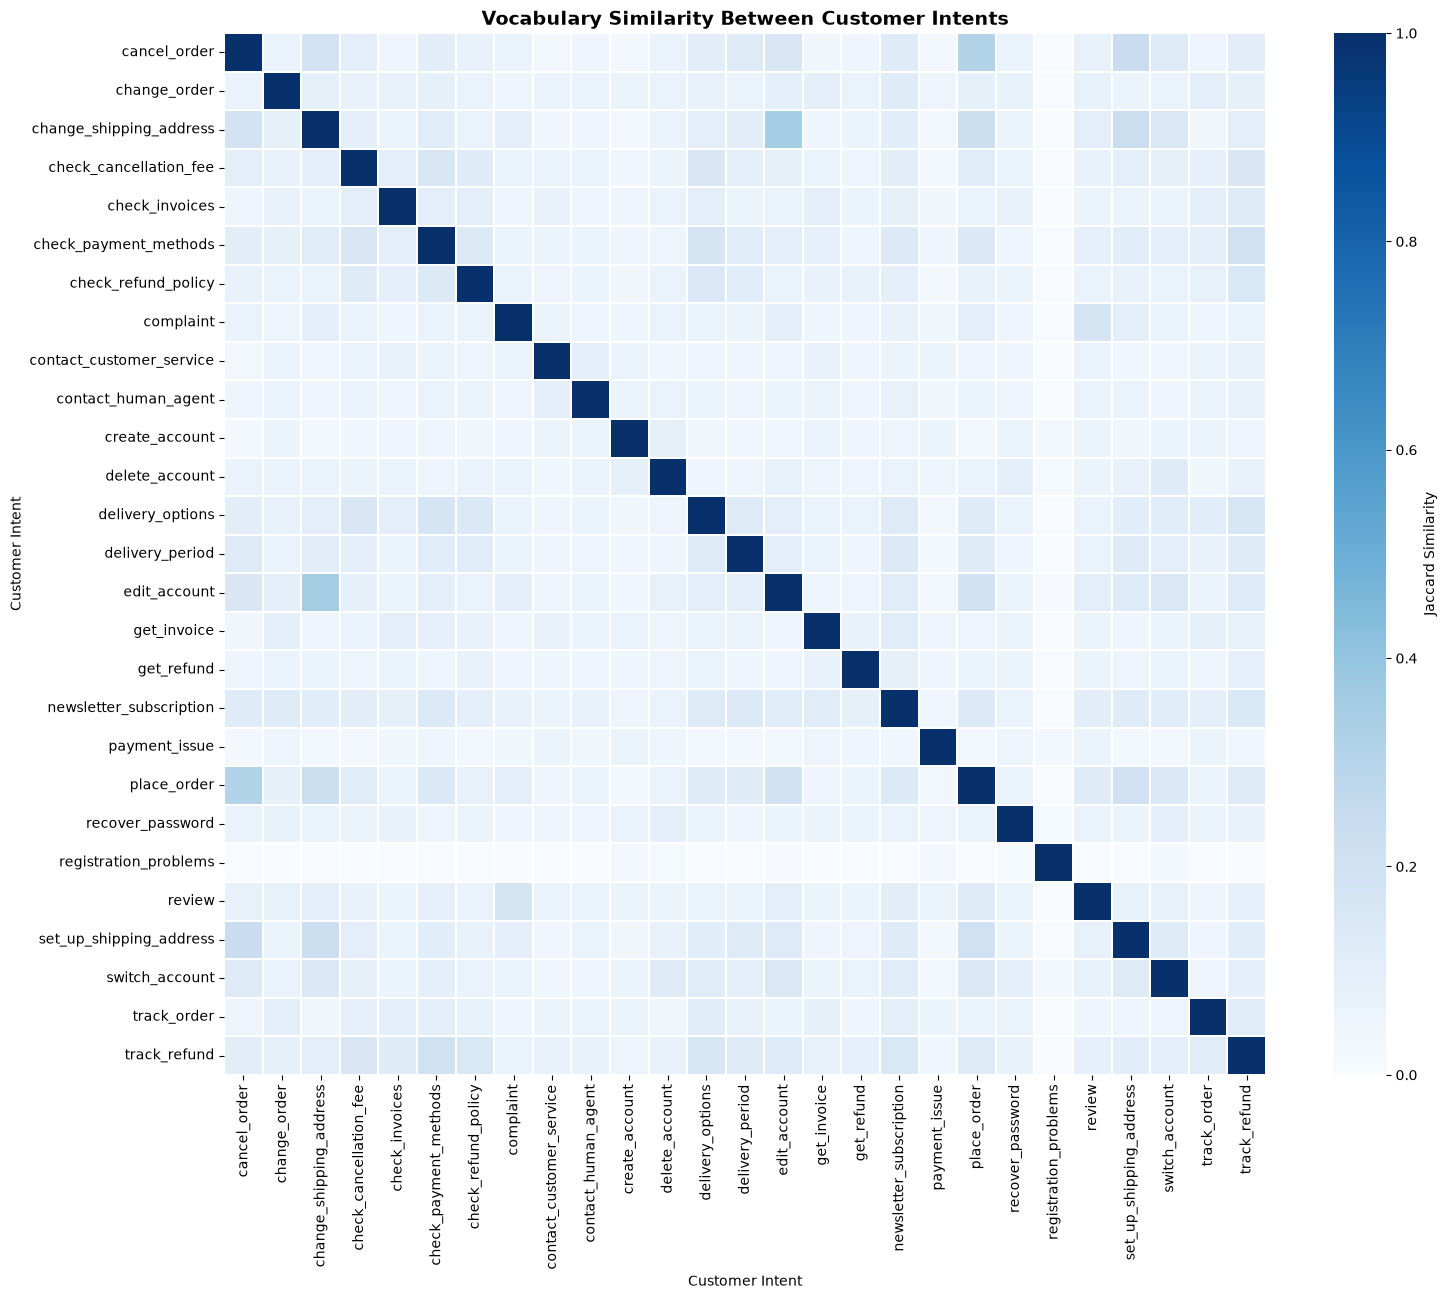

Average Pairwise Similarity: 0.074
Maximum Pairwise Similarity: 0.353
Minimum Pairwise Similarity: 0.000


In [16]:
similarity_matrix = pd.DataFrame(
    np.eye(len(intents)),
    index=intents,
    columns=intents
)

for _, row in vocabulary_overlap.iterrows():
    similarity_matrix.loc[
        row["Intent A"], row["Intent B"]
    ] = row["Jaccard Similarity"]
    similarity_matrix.loc[
        row["Intent B"], row["Intent A"]
    ] = row["Jaccard Similarity"]

plt.figure(figsize=(16, 13))
sns.heatmap(
    similarity_matrix,
    cmap="Blues",
    linewidths=0.3,
    square=True,
    cbar_kws={"label": "Jaccard Similarity"}
)
plt.title("Vocabulary Similarity Between Customer Intents", fontsize=14, fontweight="bold")
plt.xlabel("Customer Intent")
plt.ylabel("Customer Intent")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

print(f"Average Pairwise Similarity: {vocabulary_overlap['Jaccard Similarity'].mean():.3f}")
print(f"Maximum Pairwise Similarity: {vocabulary_overlap['Jaccard Similarity'].max():.3f}")
print(f"Minimum Pairwise Similarity: {vocabulary_overlap['Jaccard Similarity'].min():.3f}")

#### Observations
- **Average pairwise similarity is 0.074**, indicating relatively limited vocabulary overlap across customer intents.
- **Similarity ranges from 0.000 to 0.353**, revealing considerable variation in shared vocabulary between intent pairs.
- **Key Finding:** Most intents have relatively distinct vocabularies, while a smaller number of overlapping intent pairs may require contextual features for reliable classification.

#### Examining Most Frequent Bigrams in Customer Utterances

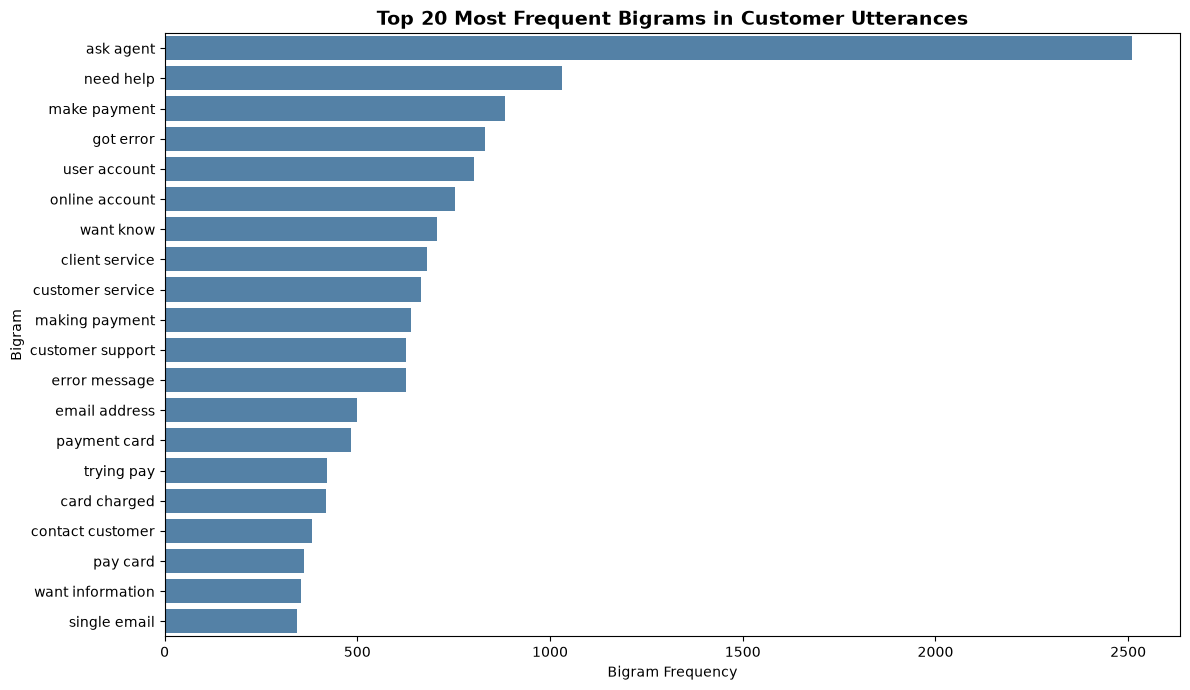

,Bigram,Frequency
133,ask agent,2509
964,need help,1031
895,make payment,882
485,got error,831
1571,user account,804
1015,online account,753
1682,want know,706
271,client service,681
319,customer service,666
904,making payment,638


In [17]:
from sklearn.feature_extraction.text import CountVectorizer

bigram_vectorizer = CountVectorizer(
    ngram_range=(2, 2),
    stop_words="english",
    min_df=2
)

bigram_matrix = bigram_vectorizer.fit_transform(df["utterance"])

bigram_frequencies = np.asarray(
    bigram_matrix.sum(axis=0)
).ravel()

bigram_summary = (
    pd.DataFrame({
        "Bigram": bigram_vectorizer.get_feature_names_out(),
        "Frequency": bigram_frequencies
    })
    .sort_values("Frequency", ascending=False)
    .head(20)
)

plt.figure(figsize=(12, 7))
sns.barplot(
    data=bigram_summary,
    x="Frequency",
    y="Bigram",
    color="steelblue"
)
plt.title("Top 20 Most Frequent Bigrams in Customer Utterances", fontsize=14, fontweight="bold")
plt.xlabel("Bigram Frequency")
plt.ylabel("Bigram")
plt.tight_layout()
plt.show()

display(bigram_summary)

#### Observations
- **`ask agent` (2,509)** is the most frequent bigram, followed by `need help` (1,031) and `make payment` (882).
- **Payment-related phrases** such as `got error`, `making payment`, and `card charged` highlight recurring transaction issues, while `customer service` and `customer support` reflect support-related requests.
- **Key Finding:** Bigrams capture meaningful word combinations that individual tokens may miss, supporting the evaluation of unigram and bigram TF-IDF features during modeling.

#### Examining Frequently Occurring Bigrams Across Customer Intents

In [18]:
intent_bigram_results = []

for intent, group in df.groupby("intent"):
    vectorizer = CountVectorizer(
        ngram_range=(2, 2),
        stop_words="english"
    )

    matrix = vectorizer.fit_transform(group["utterance"])
    frequencies = np.asarray(matrix.sum(axis=0)).ravel()

    top_indices = frequencies.argsort()[::-1][:5]
    features = vectorizer.get_feature_names_out()

    top_bigrams = [
        f"{features[i]} ({frequencies[i]})"
        for i in top_indices
    ]

    intent_bigram_results.append({
        "Intent": intent,
        "Top 5 Bigrams": ", ".join(top_bigrams)
    })

intent_bigram_summary = pd.DataFrame(intent_bigram_results)
display(intent_bigram_summary)

,Intent,Top 5 Bigrams
0,cancel_order,"cancel order (19), cancel purchase (13), want ..."
1,change_order,"change purchase (182), modify purchase (182), ..."
2,change_shipping_address,"shipping address (105), ask agent (25), update..."
3,check_cancellation_fee,"check cancellation (91), cancellation penalty ..."
4,check_invoices,"didn receive (175), ask agent (137), need help..."
5,check_payment_methods,"payment methods (108), payment options (88), a..."
6,check_refund_policy,"refund policy (113), money policy (109), reimb..."
7,complaint,"consumer complaint (344), complaint service (1..."
8,contact_customer_service,"client service (681), customer service (666), ..."
9,contact_human_agent,"human agent (246), talk human (150), speak hum..."


#### Observations
- **Intent-specific phrases** such as `cancel order`, `payment methods`, `refund policy`, and `account password` clearly reflect different customer support requests.
- **Related intents share certain phrases**, particularly `shipping address` across address-related intents and `user account` across account management intents.
- **Key Finding:** Bigrams provide useful contextual information, supporting the evaluation of word-level TF-IDF with unigram and bigram combinations during model development.

## 5. Text Repetition Analysis

#### Examining Duplicate Customer Utterances Across Intents

In [19]:
duplicate_utterances = df[
    df.duplicated(subset=["utterance"], keep=False)
].copy()

duplicate_summary = (
    duplicate_utterances.groupby("intent")
    .agg(
        Duplicate_Rows=("utterance", "size"),
        Unique_Duplicated_Utterances=("utterance", "nunique")
    )
    .sort_values("Duplicate_Rows", ascending=False)
)

print(f"Total Rows Involved in Duplicates: {len(duplicate_utterances)}")
print(f"Unique Utterances Repeated: {duplicate_utterances['utterance'].nunique()}")
print(f"Extra Duplicate Rows: {df.duplicated(subset=['utterance']).sum()}")

display(duplicate_summary)

Total Rows Involved in Duplicates: 42
Unique Utterances Repeated: 21
Extra Duplicate Rows: 21


,Duplicate_Rows,Unique_Duplicated_Utterances
intent,,
get_invoice,18,9
track_order,10,5
check_refund_policy,6,3
change_order,4,2
check_cancellation_fee,2,1
payment_issue,2,1


#### Observations
- **21 unique utterances are repeated**, resulting in 42 rows involved in duplication and 21 additional duplicate records.
- **`get_invoice` (18 rows)** and **`track_order` (10 rows)** contain the most duplicated records, followed by `check_refund_policy` (6 rows).
- **Decision:** Remove duplicate utterances before train-test splitting to prevent identical customer queries from appearing in both datasets and inflating evaluation performance.

#### Examining Highly Similar Customer Utterances Across Different Intents

In [20]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import NearestNeighbors

unique_df = df.drop_duplicates(subset=["utterance"]).reset_index(drop=True)

similarity_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

X_similarity = similarity_vectorizer.fit_transform(unique_df["utterance"])

neighbors = NearestNeighbors(
    n_neighbors=10,
    metric="cosine",
    algorithm="brute",
    n_jobs=-1
)
neighbors.fit(X_similarity)

distances, indices = neighbors.kneighbors(X_similarity)

similar_pairs = []

for i in range(len(unique_df)):
    for distance, j in zip(distances[i], indices[i]):
        if i >= j:
            continue

        if unique_df.at[i, "intent"] == unique_df.at[j, "intent"]:
            continue

        similarity = 1 - distance

        if similarity >= 0.80:
            similar_pairs.append({
                "Utterance A": unique_df.at[i, "utterance"],
                "Intent A": unique_df.at[i, "intent"],
                "Utterance B": unique_df.at[j, "utterance"],
                "Intent B": unique_df.at[j, "intent"],
                "Cosine Similarity": round(similarity, 3)
            })

similarity_results = (
    pd.DataFrame(similar_pairs)
    .sort_values("Cosine Similarity", ascending=False)
    if similar_pairs
    else pd.DataFrame(columns=[
        "Utterance A", "Intent A", "Utterance B",
        "Intent B", "Cosine Similarity"
    ])
)

print(f"Cross-Intent Similar Pairs Found: {len(similarity_results)}")
display(similarity_results.head(10))

Cross-Intent Similar Pairs Found: 252


,Utterance A,Intent A,Utterance B,Intent B,Cosine Similarity
0,can i register?,create_account,I can't register,registration_problems,1.000
17,when will my tickket arrive ?,delivery_period,when will my order arrive?,track_order,0.948
100,how to view the status of my order,track_order,how to view the status of my reimbursemernt,track_refund,0.938
2,how can I create a profile?,create_account,I can't create a profile,registration_problems,0.929
18,when will my tickket arrive ?,delivery_period,when will my delivery arrive?,track_order,0.904
226,can you give me information about the status o...,track_order,can you give me information about the status o...,track_refund,0.900
227,can you give me information about the status o...,track_order,can you give me information about the status o...,track_refund,0.899
10,how do I change my profilr?,edit_account,how do I change my order?,change_order,0.898
39,I need help checking my invoice,check_invoices,I need help checking my deliveried,track_order,0.898
26,I need help checking my bill,check_invoices,I need help checking my deliveried,track_order,0.898


#### Observations
- **Highly similar utterances occur across different intents**, including `create_account` versus `registration_problems` and `track_order` versus `track_refund`.
- **A cosine similarity of 1.000** between `can i register?` and `I can't register` exposes a limitation of the current word-level TF-IDF representation in capturing negation.
- **Key Finding:** Intent classification must distinguish subtle wording changes, negation, and domain-specific terms, supporting comparisons of word n-grams and character-level TF-IDF features.

#### Summarizing Highly Similar Cross-Intent Utterances

In [21]:
print(f"Cross-Intent Pairs (Similarity >= 0.80): {len(similarity_results)}")
print(f"Cross-Intent Pairs (Similarity >= 0.90): {(similarity_results['Cosine Similarity'] >= 0.90).sum()}")
print(f"Cross-Intent Pairs (Similarity >= 0.95): {(similarity_results['Cosine Similarity'] >= 0.95).sum()}")

if not similarity_results.empty:
    pair_summary = similarity_results.copy()

    pair_summary["Intent Pair"] = pair_summary.apply(
        lambda row: " | ".join(sorted([row["Intent A"], row["Intent B"]])),
        axis=1
    )

    pair_counts = (
        pair_summary["Intent Pair"]
        .value_counts()
        .head(10)
        .rename_axis("Intent Pair")
        .reset_index(name="Similar Pairs")
    )

    display(pair_counts)

Cross-Intent Pairs (Similarity >= 0.80): 252
Cross-Intent Pairs (Similarity >= 0.90): 6
Cross-Intent Pairs (Similarity >= 0.95): 1


,Intent Pair,Similar Pairs
0,track_order | track_refund,193
1,check_invoices | track_order,28
2,change_order | edit_account,5
3,change_order | track_order,5
4,create_account | registration_problems,4
5,delivery_period | track_order,4
6,change_shipping_address | edit_account,3
7,complaint | review,2
8,change_order | change_shipping_address,2
9,delivery_options | delivery_period,2


#### Observations
- **252 cross-intent utterance pairs** were detected with cosine similarity ≥ 0.80, including 6 pairs ≥ 0.90 and 1 pair ≥ 0.95.
- **`track_order` and `track_refund` account for 193 detected pairs**, followed by `check_invoices` and `track_order` with 28 pairs.
- **Key Finding:** Closely related customer requests can share highly similar sentence structures, highlighting the importance of evaluating per-class performance and confusion patterns during model evaluation.

## 6. Key Findings and Modeling Implications

- **Class Imbalance:** The 27 customer intents have substantially different sample sizes, requiring stratified data splitting and class-sensitive evaluation metrics.
- **Text Characteristics:** Customer utterances are generally short, with varying lengths, informal expressions, and occasional spelling inconsistencies.
- **Vocabulary Patterns:** Intent-specific keywords and bigrams provide useful signals, although related intents share overlapping terminology.
- **Text Similarity:** Highly similar requests can represent different intents, particularly in order tracking, refund tracking, and account registration.
- **Data Quality:** Duplicate utterances should be removed before train-test splitting to reduce evaluation leakage.
- **Modeling Direction:** Evaluate word-level and character-level TF-IDF representations with CPU-efficient classification models, emphasizing macro F1-score, per-class recall, and confusion matrix analysis.